# Data Visualization in 50 Examples (Matplotlib)

Run all cells top to bottom.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (7, 4.2),
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Basic Charts

### 1. Simple line plot

The starting point: one line, a title and labelled axes.

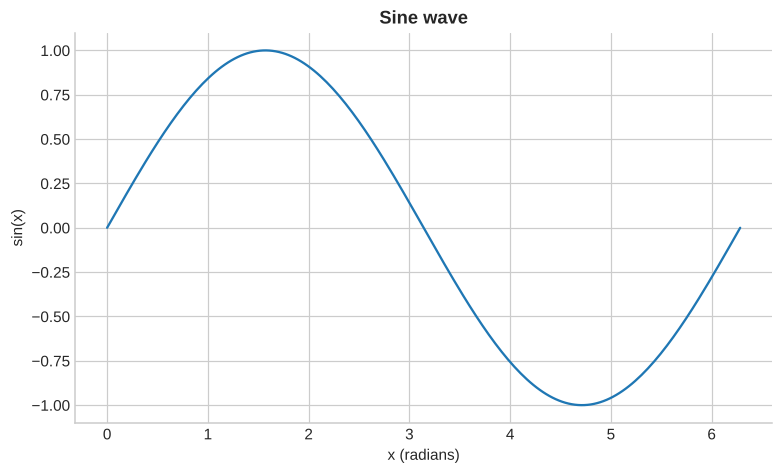

In [1]:
x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x))
ax.set(title="Sine wave", xlabel="x (radians)", ylabel="sin(x)")

### 2. Multiple lines with a legend

Give each series a `label` and call `legend()`.

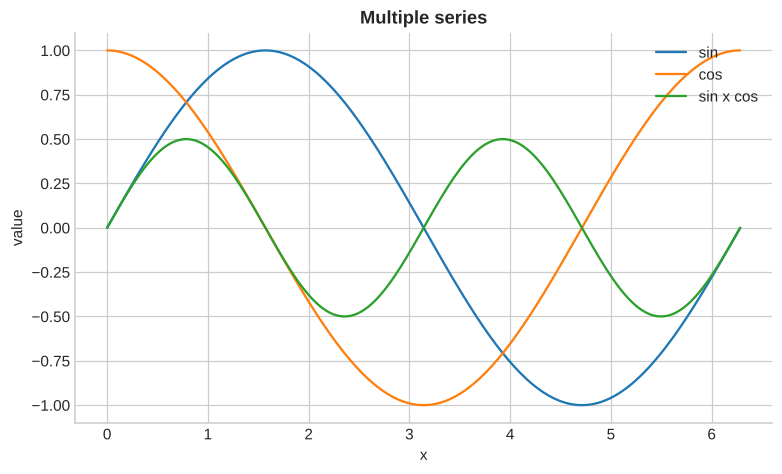

In [2]:
x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label="sin")
ax.plot(x, np.cos(x), label="cos")
ax.plot(x, np.sin(x) * np.cos(x), label="sin x cos")
ax.legend(loc="upper right")
ax.set(title="Multiple series", xlabel="x", ylabel="value")

### 3. Line styles and markers

Format strings combine marker, line style and colour in one go.

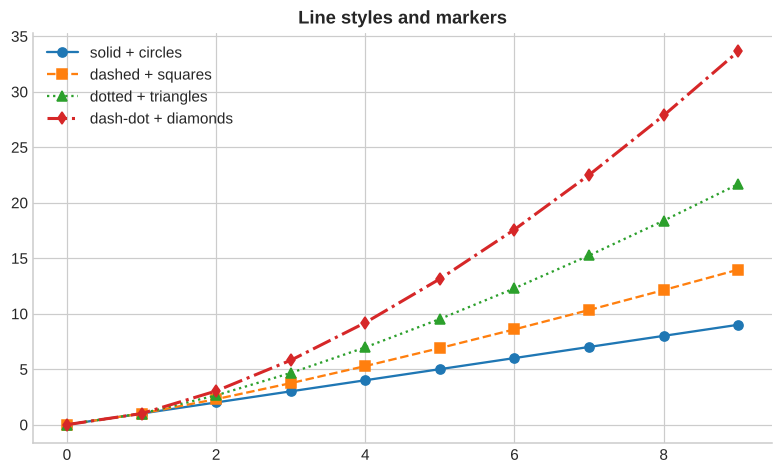

In [3]:
x = np.arange(10)
fig, ax = plt.subplots()
ax.plot(x, x, "o-", color="tab:blue", label="solid + circles")
ax.plot(x, x ** 1.2, "s--", color="tab:orange", label="dashed + squares")
ax.plot(x, x ** 1.4, "^:", color="tab:green", label="dotted + triangles")
ax.plot(x, x ** 1.6, "d-.", color="tab:red", linewidth=2, markersize=6, label="dash-dot + diamonds")
ax.legend()
ax.set_title("Line styles and markers")

### 4. Scatter plot

Use `alpha` and a white edge to keep overlapping points readable.

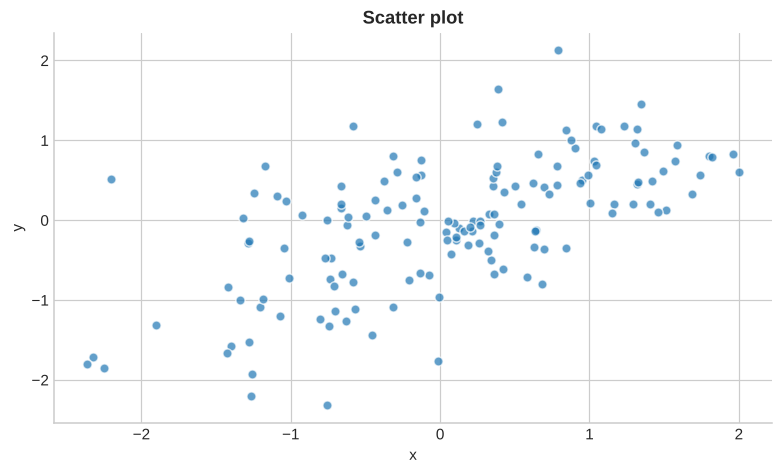

In [4]:
rng = np.random.default_rng(0)
x = rng.normal(size=150)
y = 0.6 * x + rng.normal(scale=0.6, size=150)
fig, ax = plt.subplots()
ax.scatter(x, y, alpha=0.7, edgecolor="white")
ax.set(title="Scatter plot", xlabel="x", ylabel="y")

### 5. Bubble chart with colorbar

Encode two extra variables: marker size and colour.

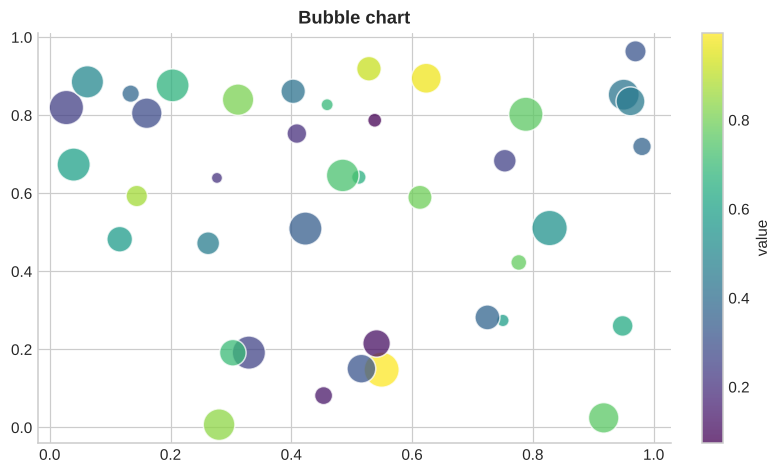

In [5]:
rng = np.random.default_rng(1)
x, y = rng.random(40), rng.random(40)
size = rng.integers(50, 600, 40)
color = rng.random(40)
fig, ax = plt.subplots()
sc = ax.scatter(x, y, s=size, c=color, cmap="viridis", alpha=0.75, edgecolor="white")
fig.colorbar(sc, ax=ax, label="value")
ax.set_title("Bubble chart")

### 6. Bar chart with value labels

`bar_label` prints the value on top of each bar.

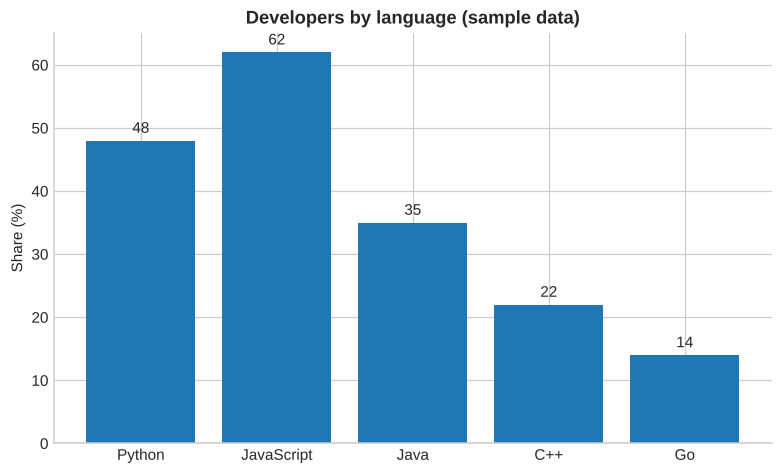

In [6]:
langs = ["Python", "JavaScript", "Java", "C++", "Go"]
users = [48, 62, 35, 22, 14]
fig, ax = plt.subplots()
bars = ax.bar(langs, users, color="tab:blue")
ax.bar_label(bars, padding=3)
ax.set(title="Developers by language (sample data)", ylabel="Share (%)")

### 7. Sorted horizontal bar chart

Horizontal bars are best for long labels, and sorting makes ranking obvious.

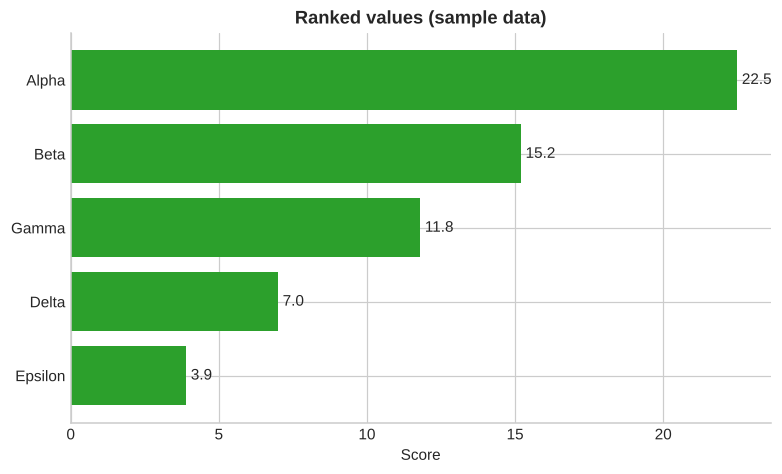

In [7]:
data = {"Alpha": 22.5, "Beta": 15.2, "Gamma": 11.8, "Delta": 7.0, "Epsilon": 3.9}
names, vals = zip(*sorted(data.items(), key=lambda kv: kv[1]))
fig, ax = plt.subplots()
bars = ax.barh(names, vals, color="tab:green")
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set(title="Ranked values (sample data)", xlabel="Score")

### 8. Grouped bar chart

Offset the bars by half a bar width to place groups side by side.

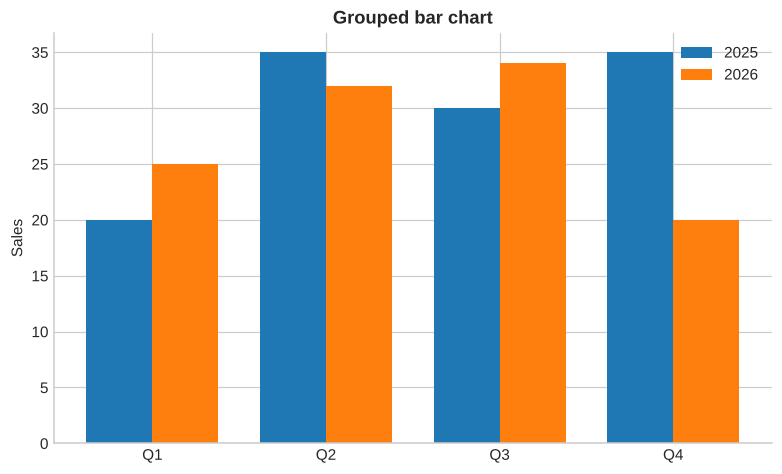

In [8]:
labels = ["Q1", "Q2", "Q3", "Q4"]
a = [20, 35, 30, 35]
b = [25, 32, 34, 20]
x = np.arange(len(labels))
w = 0.38
fig, ax = plt.subplots()
ax.bar(x - w / 2, a, w, label="2025")
ax.bar(x + w / 2, b, w, label="2026")
ax.set_xticks(x, labels)
ax.legend()
ax.set(title="Grouped bar chart", ylabel="Sales")

## Distributions

### 9. Histogram with mean line

Pick the bin count deliberately and mark a reference value.

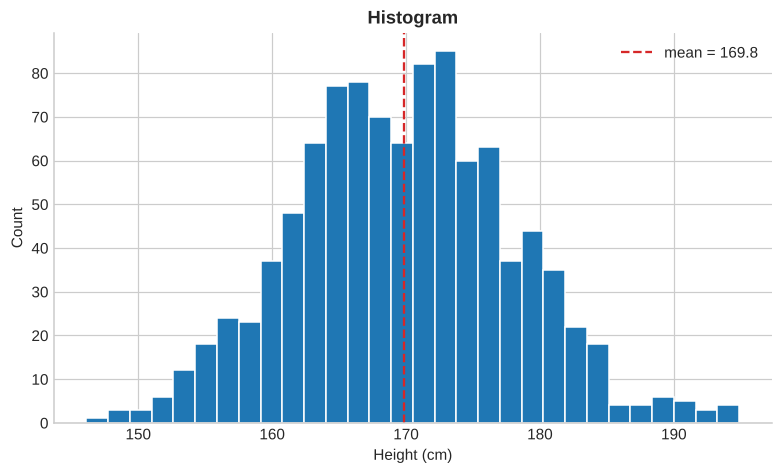

In [9]:
rng = np.random.default_rng(2)
data = rng.normal(170, 8, 1000)
fig, ax = plt.subplots()
ax.hist(data, bins=30, color="tab:blue", edgecolor="white")
ax.axvline(data.mean(), color="tab:red", linestyle="--", label=f"mean = {data.mean():.1f}")
ax.legend()
ax.set(title="Histogram", xlabel="Height (cm)", ylabel="Count")

### 10. Histogram with kernel density estimate

A Gaussian KDE computed with plain NumPy, no SciPy needed.

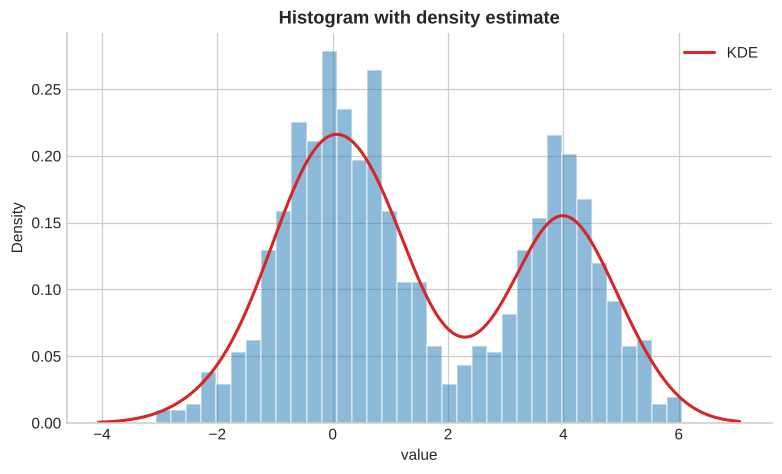

In [10]:
rng = np.random.default_rng(3)
data = np.concatenate([rng.normal(0, 1, 500), rng.normal(4, 0.8, 300)])
xs = np.linspace(data.min() - 1, data.max() + 1, 400)
h = 1.06 * data.std() * len(data) ** (-1 / 5)      # Silverman's rule
kde = np.exp(-0.5 * ((xs[:, None] - data[None, :]) / h) ** 2).sum(axis=1)
kde /= len(data) * h * np.sqrt(2 * np.pi)
fig, ax = plt.subplots()
ax.hist(data, bins=35, density=True, alpha=0.5, edgecolor="white")
ax.plot(xs, kde, color="tab:red", linewidth=2, label="KDE")
ax.legend()
ax.set(title="Histogram with density estimate", xlabel="value", ylabel="Density")

### 11. Box plot

Compare spread, median and outliers across groups.

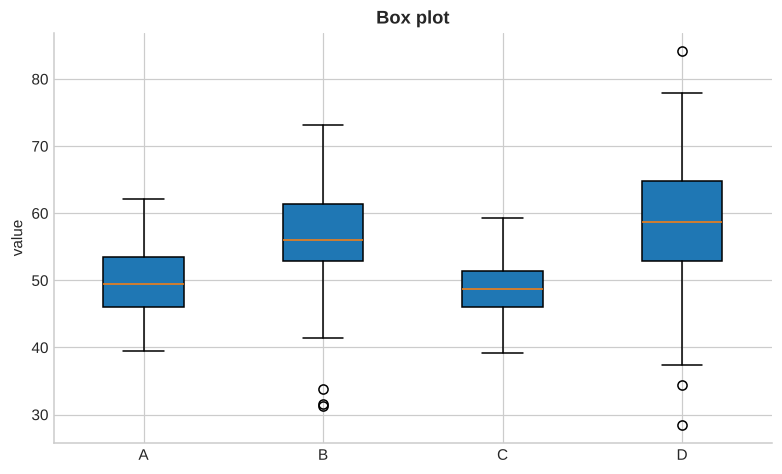

In [11]:
rng = np.random.default_rng(4)
groups = [rng.normal(m, s, 100) for m, s in [(50, 5), (55, 8), (48, 4), (60, 10)]]
fig, ax = plt.subplots()
ax.boxplot(groups, patch_artist=True)
ax.set_xticks([1, 2, 3, 4], ["A", "B", "C", "D"])
ax.set(title="Box plot", ylabel="value")

### 12. Violin plot

Like a box plot, but shows the whole shape of each distribution.

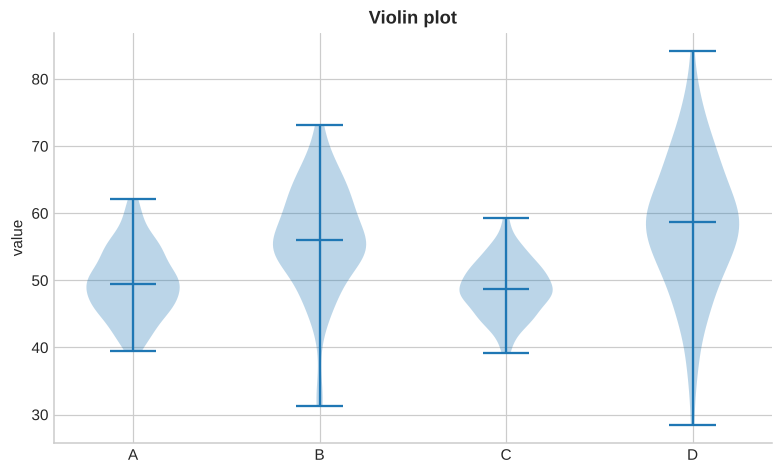

In [12]:
rng = np.random.default_rng(4)
groups = [rng.normal(m, s, 100) for m, s in [(50, 5), (55, 8), (48, 4), (60, 10)]]
fig, ax = plt.subplots()
ax.violinplot(groups, showmedians=True)
ax.set_xticks([1, 2, 3, 4], ["A", "B", "C", "D"])
ax.set(title="Violin plot", ylabel="value")

### 13. Overlapping histograms

Use `density=True` and transparency to compare groups of different sizes.

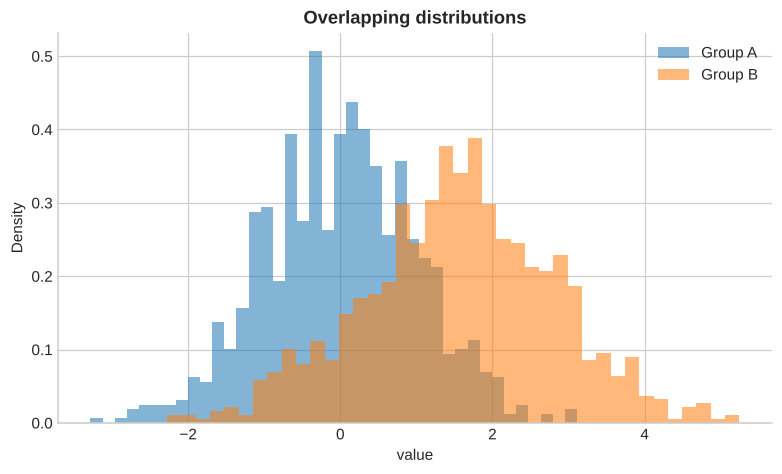

In [13]:
rng = np.random.default_rng(5)
a = rng.normal(0, 1, 1000)
b = rng.normal(1.5, 1.3, 1000)
fig, ax = plt.subplots()
ax.hist(a, bins=40, density=True, alpha=0.55, label="Group A")
ax.hist(b, bins=40, density=True, alpha=0.55, label="Group B")
ax.legend()
ax.set(title="Overlapping distributions", xlabel="value", ylabel="Density")

### 14. Empirical CDF

Shows the proportion of data below each value, with no binning choices.

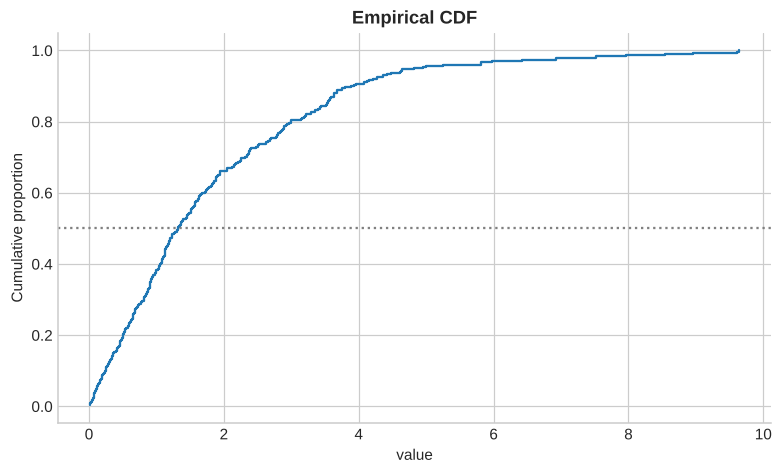

In [14]:
rng = np.random.default_rng(6)
data = np.sort(rng.exponential(2.0, 300))
y = np.arange(1, len(data) + 1) / len(data)
fig, ax = plt.subplots()
ax.step(data, y, where="post")
ax.axhline(0.5, color="gray", linestyle=":")
ax.set(title="Empirical CDF", xlabel="value", ylabel="Cumulative proportion")

### 15. Hexbin density plot

Avoids overplotting when you have thousands of points.

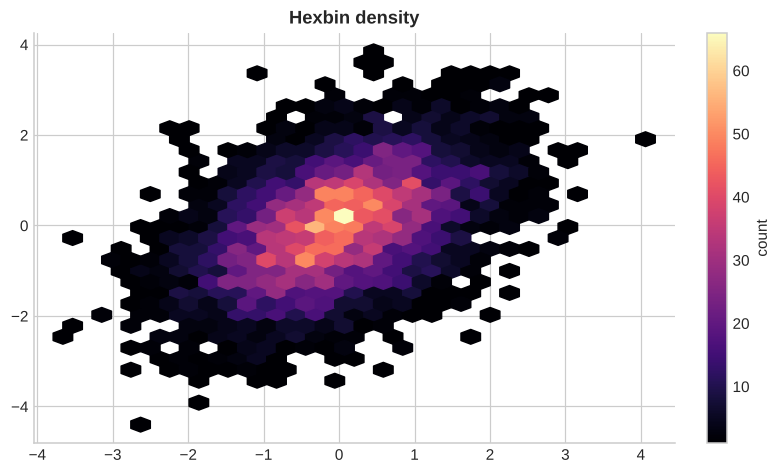

In [15]:
rng = np.random.default_rng(7)
x = rng.normal(size=5000)
y = x * 0.5 + rng.normal(size=5000)
fig, ax = plt.subplots()
hb = ax.hexbin(x, y, gridsize=30, cmap="magma", mincnt=1)
fig.colorbar(hb, ax=ax, label="count")
ax.set_title("Hexbin density")

### 16. 2D histogram

Square bins give a heatmap of where the data concentrates.

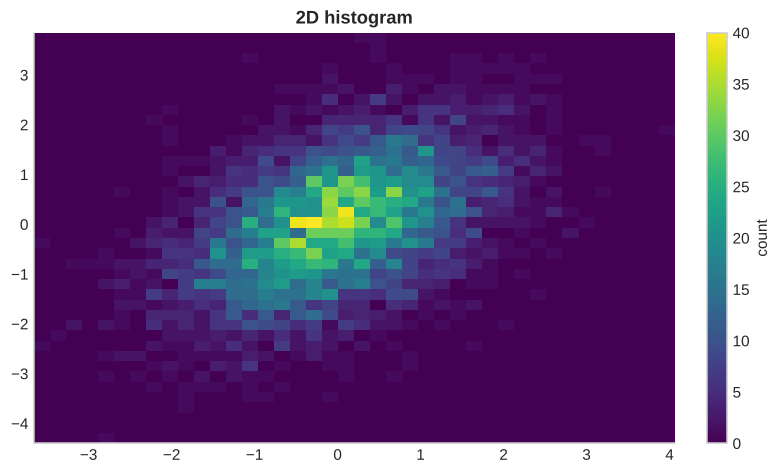

In [16]:
rng = np.random.default_rng(7)
x = rng.normal(size=5000)
y = x * 0.5 + rng.normal(size=5000)
fig, ax = plt.subplots()
counts, xedges, yedges, img = ax.hist2d(x, y, bins=40, cmap="viridis")
fig.colorbar(img, ax=ax, label="count")
ax.set_title("2D histogram")

## Composition & Ranking

### 17. Pie chart

Use sparingly, with few slices and clear labels.

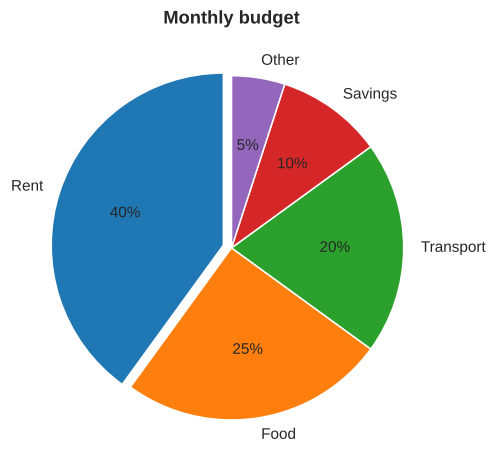

In [17]:
sizes = [40, 25, 20, 10, 5]
labels = ["Rent", "Food", "Transport", "Savings", "Other"]
fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct="%1.0f%%", startangle=90,
       explode=[0.05, 0, 0, 0, 0], wedgeprops={"edgecolor": "white"})
ax.set_title("Monthly budget")

### 18. Donut chart

A pie with a hole, leaving room for a headline number or label.

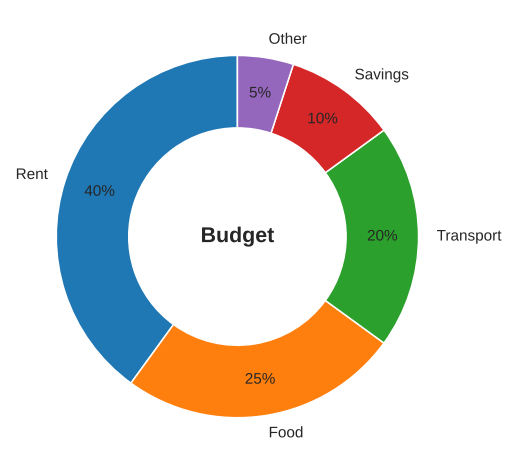

In [18]:
sizes = [40, 25, 20, 10, 5]
labels = ["Rent", "Food", "Transport", "Savings", "Other"]
fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct="%1.0f%%", startangle=90, pctdistance=0.8,
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.text(0, 0, "Budget", ha="center", va="center", fontsize=14, fontweight="bold")

### 19. Stacked bar chart

Use the `bottom` argument to stack one series on another.

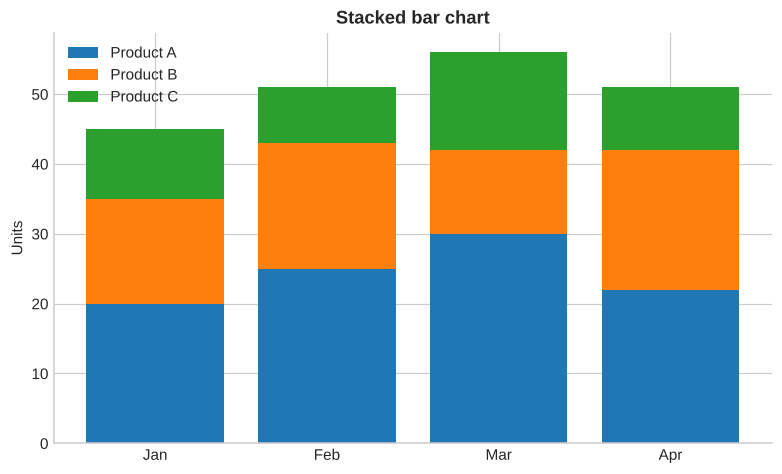

In [19]:
months = ["Jan", "Feb", "Mar", "Apr"]
a = np.array([20, 25, 30, 22])
b = np.array([15, 18, 12, 20])
c = np.array([10, 8, 14, 9])
fig, ax = plt.subplots()
ax.bar(months, a, label="Product A")
ax.bar(months, b, bottom=a, label="Product B")
ax.bar(months, c, bottom=a + b, label="Product C")
ax.legend()
ax.set(title="Stacked bar chart", ylabel="Units")

### 20. 100% stacked bar chart

Normalise each bar to compare proportions instead of totals.

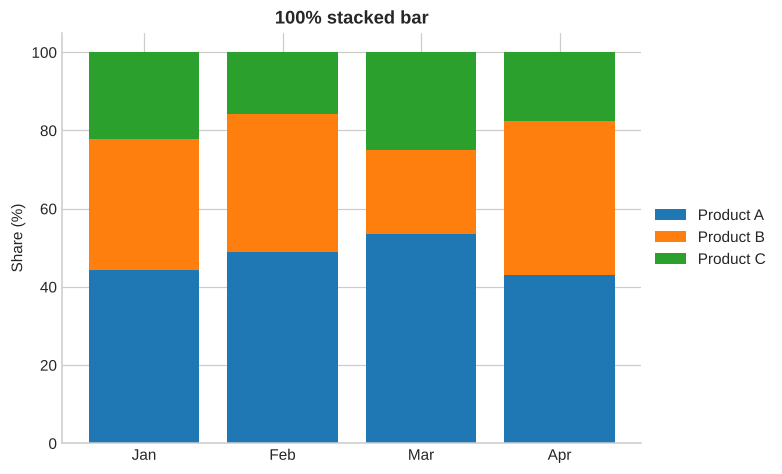

In [20]:
months = ["Jan", "Feb", "Mar", "Apr"]
a = np.array([20, 25, 30, 22])
b = np.array([15, 18, 12, 20])
c = np.array([10, 8, 14, 9])
totals = a + b + c
fig, ax = plt.subplots()
bottom = np.zeros(4)
for vals, name in [(a, "Product A"), (b, "Product B"), (c, "Product C")]:
    share = vals / totals * 100
    ax.bar(months, share, bottom=bottom, label=name)
    bottom += share
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set(title="100% stacked bar", ylabel="Share (%)")

### 21. Stacked area chart

Shows how the total and its parts change over time.

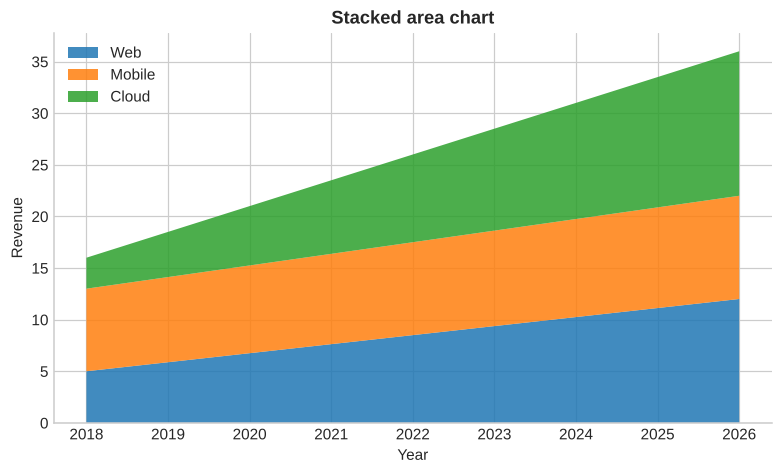

In [21]:
x = np.arange(2018, 2027)
y1 = np.linspace(5, 12, 9)
y2 = np.linspace(8, 10, 9)
y3 = np.linspace(3, 14, 9)
fig, ax = plt.subplots()
ax.stackplot(x, y1, y2, y3, labels=["Web", "Mobile", "Cloud"], alpha=0.85)
ax.legend(loc="upper left")
ax.set(title="Stacked area chart", xlabel="Year", ylabel="Revenue")

### 22. Lollipop chart

A lighter alternative to bars for ranked values.

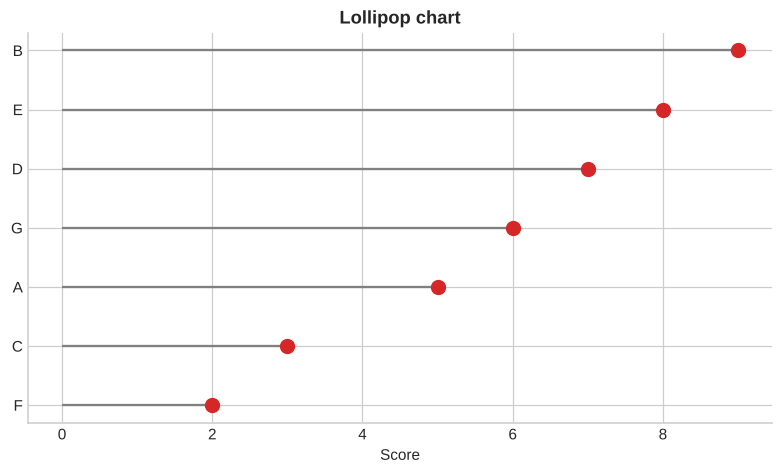

In [22]:
names = np.array(list("ABCDEFG"))
vals = np.array([5, 9, 3, 7, 8, 2, 6])
order = np.argsort(vals)
ypos = np.arange(len(vals))
fig, ax = plt.subplots()
ax.hlines(ypos, 0, vals[order], color="gray")
ax.plot(vals[order], ypos, "o", markersize=9, color="tab:red")
ax.set_yticks(ypos, names[order])
ax.set(title="Lollipop chart", xlabel="Score")

## Time Series

### 23. Time series with date axis

NumPy `datetime64` values work directly, and `mdates` controls tick format.

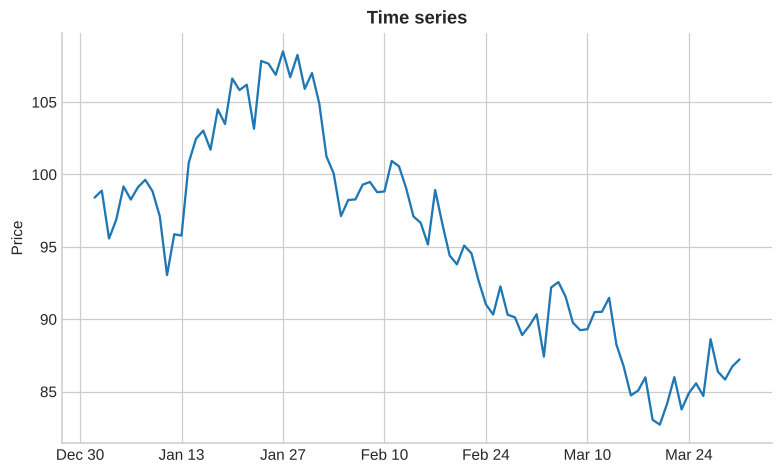

In [23]:
import matplotlib.dates as mdates

rng = np.random.default_rng(9)
dates = np.arange("2026-01-01", "2026-04-01", dtype="datetime64[D]")
values = 100 + rng.normal(0, 2, len(dates)).cumsum()
fig, ax = plt.subplots()
ax.plot(dates, values)
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set(title="Time series", ylabel="Price")

### 24. Moving average overlay

Smooth noisy data and keep the raw series faded behind it.

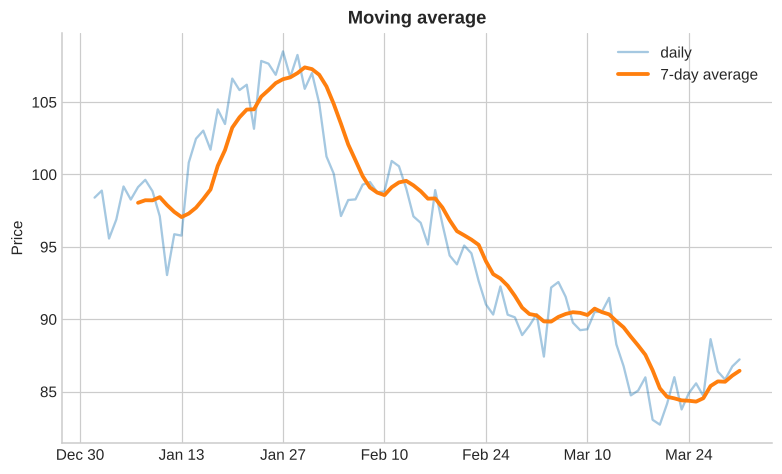

In [24]:
import matplotlib.dates as mdates

rng = np.random.default_rng(9)
dates = np.arange("2026-01-01", "2026-04-01", dtype="datetime64[D]")
values = 100 + rng.normal(0, 2, len(dates)).cumsum()
window = 7
ma = np.convolve(values, np.ones(window) / window, mode="valid")
fig, ax = plt.subplots()
ax.plot(dates, values, alpha=0.4, label="daily")
ax.plot(dates[window - 1:], ma, linewidth=2.5, label="7-day average")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend()
ax.set(title="Moving average", ylabel="Price")

### 25. Confidence band with fill_between

Communicate uncertainty with a shaded region around a line.

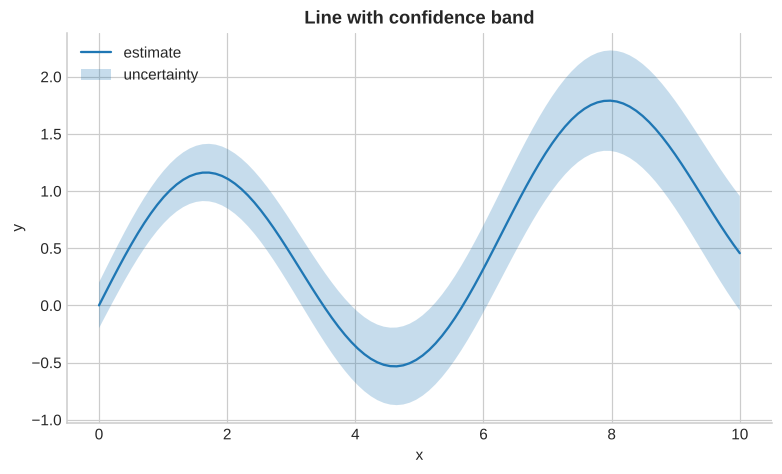

In [25]:
x = np.linspace(0, 10, 100)
y = np.sin(x) + 0.1 * x
err = 0.2 + 0.03 * x
fig, ax = plt.subplots()
ax.plot(x, y, label="estimate")
ax.fill_between(x, y - err, y + err, alpha=0.25, label="uncertainty")
ax.legend()
ax.set(title="Line with confidence band", xlabel="x", ylabel="y")

### 26. Dual-axis chart

`twinx` overlays a second y-axis. Use it carefully, with colour-matched labels.

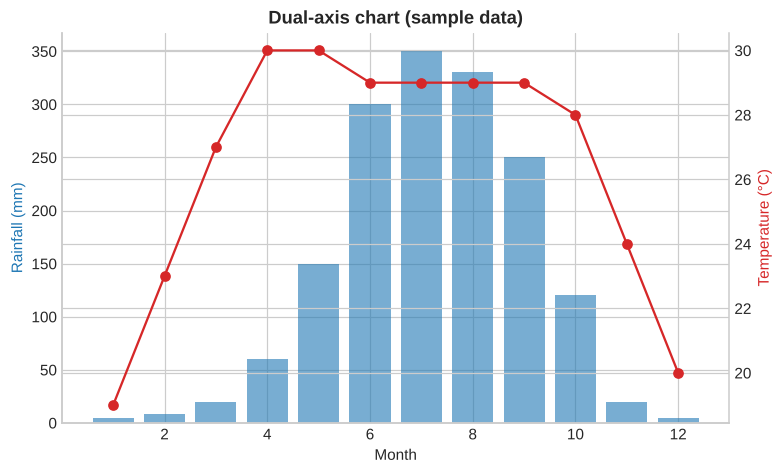

In [26]:
months = np.arange(1, 13)
rain = np.array([5, 8, 20, 60, 150, 300, 350, 330, 250, 120, 20, 5])
temp = np.array([19, 23, 27, 30, 30, 29, 29, 29, 29, 28, 24, 20])
fig, ax1 = plt.subplots()
ax1.bar(months, rain, color="tab:blue", alpha=0.6)
ax1.set_ylabel("Rainfall (mm)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(months, temp, "o-", color="tab:red")
ax2.set_ylabel("Temperature (°C)", color="tab:red")
ax2.spines["right"].set_visible(True)
ax1.set(title="Dual-axis chart (sample data)", xlabel="Month")

### 27. Annotating a peak

Point at the interesting part of the chart with `annotate`.

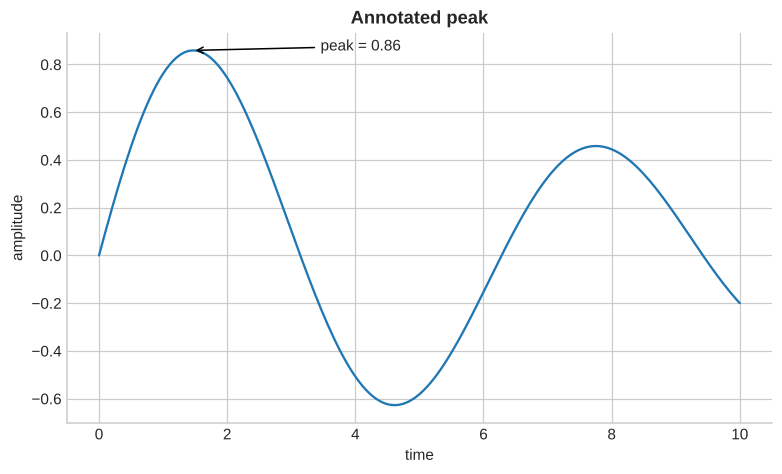

In [27]:
x = np.linspace(0, 10, 200)
y = np.sin(x) * np.exp(-0.1 * x)
i = y.argmax()
fig, ax = plt.subplots()
ax.plot(x, y)
ax.annotate(f"peak = {y[i]:.2f}", xy=(x[i], y[i]), xytext=(x[i] + 2, y[i]),
            arrowprops={"arrowstyle": "->"})
ax.set(title="Annotated peak", xlabel="time", ylabel="amplitude")

### 28. Step plot

Right for values that hold constant between changes, like prices or states.

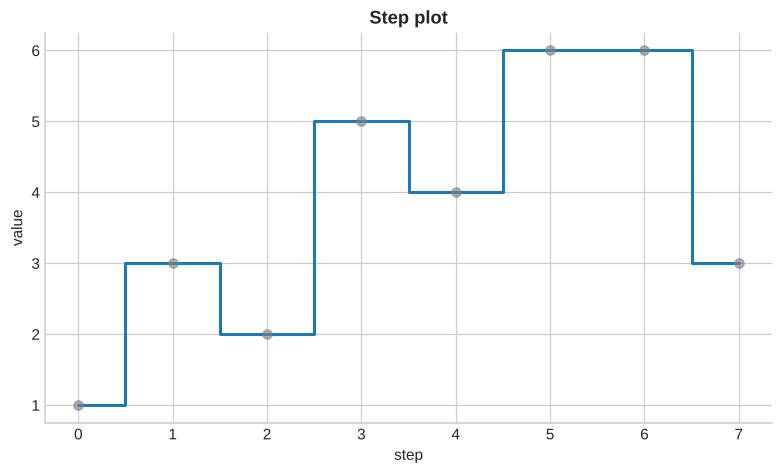

In [28]:
x = np.arange(8)
y = np.array([1, 3, 2, 5, 4, 6, 6, 3])
fig, ax = plt.subplots()
ax.step(x, y, where="mid", linewidth=2)
ax.plot(x, y, "o", color="gray", alpha=0.6)
ax.set(title="Step plot", xlabel="step", ylabel="value")

## Relationships & Surfaces

### 29. Error bars

Show measurement uncertainty with `yerr` (and `xerr`).

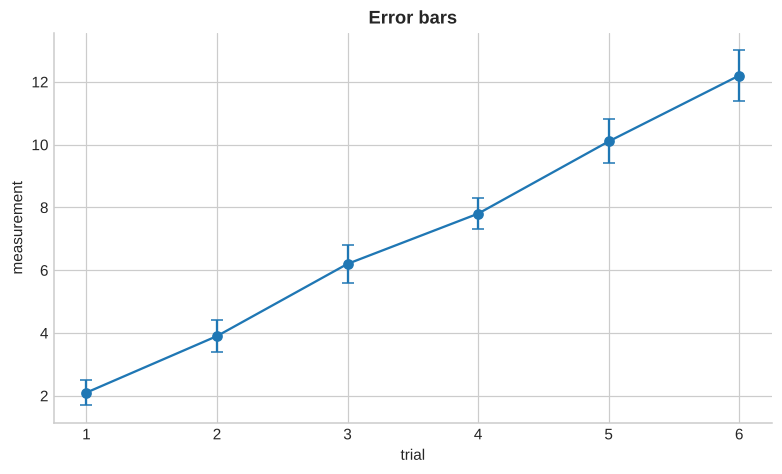

In [29]:
x = np.arange(1, 7)
y = np.array([2.1, 3.9, 6.2, 7.8, 10.1, 12.2])
err = np.array([0.4, 0.5, 0.6, 0.5, 0.7, 0.8])
fig, ax = plt.subplots()
ax.errorbar(x, y, yerr=err, fmt="o-", capsize=4)
ax.set(title="Error bars", xlabel="trial", ylabel="measurement")

### 30. Scatter with regression line

Fit a line with `np.polyfit` and report the correlation.

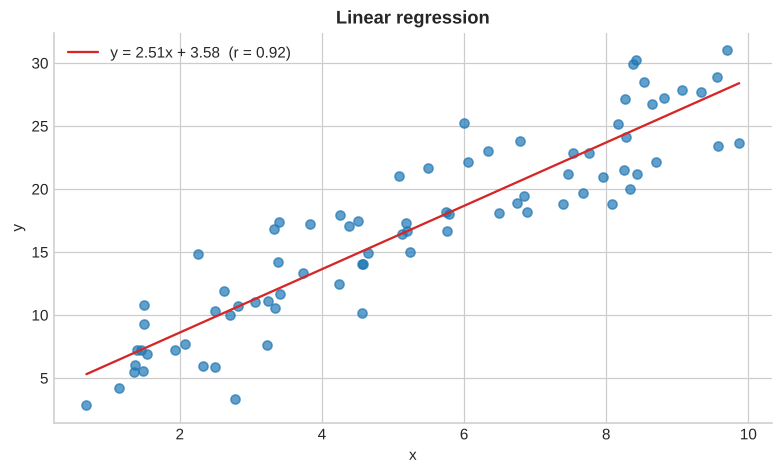

In [30]:
rng = np.random.default_rng(10)
x = rng.uniform(0, 10, 80)
y = 2.5 * x + 4 + rng.normal(0, 3, 80)
slope, intercept = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]
xs = np.array([x.min(), x.max()])
fig, ax = plt.subplots()
ax.scatter(x, y, alpha=0.7)
ax.plot(xs, slope * xs + intercept, color="tab:red",
        label=f"y = {slope:.2f}x + {intercept:.2f}  (r = {r:.2f})")
ax.legend()
ax.set(title="Linear regression", xlabel="x", ylabel="y")

### 31. Annotated correlation heatmap

`imshow` plus a text label in every cell.

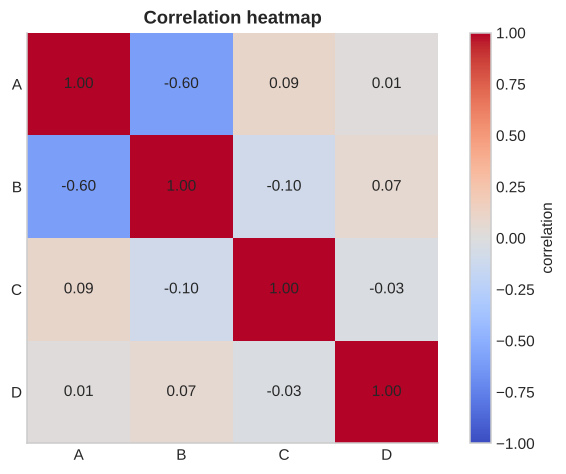

In [31]:
rng = np.random.default_rng(11)
base = rng.normal(size=(200, 1))
data = np.hstack([base + rng.normal(0, 0.5, (200, 1)),
                  -0.8 * base + rng.normal(0, 0.7, (200, 1)),
                  rng.normal(size=(200, 2))])
names = ["A", "B", "C", "D"]
corr = np.corrcoef(data, rowvar=False)
fig, ax = plt.subplots()
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(4), names)
ax.set_yticks(range(4), names)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="correlation")
ax.grid(False)
ax.set_title("Correlation heatmap")

### 32. Contour plot

Line contours with inline labels for a 2D function.

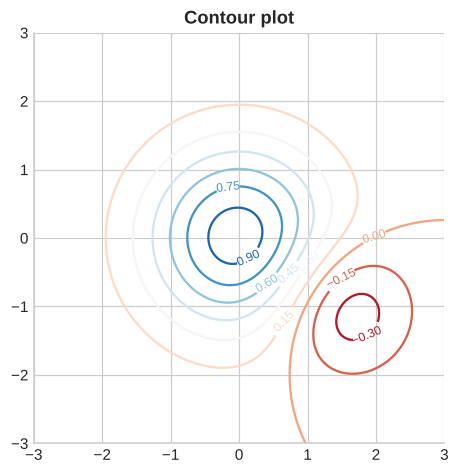

In [32]:
x = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x, x)
Z = np.exp(-(X ** 2 + Y ** 2) / 2) - 0.5 * np.exp(-((X - 1.5) ** 2 + (Y + 1) ** 2))
fig, ax = plt.subplots()
cs = ax.contour(X, Y, Z, levels=12, cmap="RdBu")
ax.clabel(cs, inline=True, fontsize=8)
ax.set_aspect("equal")
ax.set_title("Contour plot")

### 33. Filled contour plot

`contourf` fills the regions between levels, and a colorbar gives the scale.

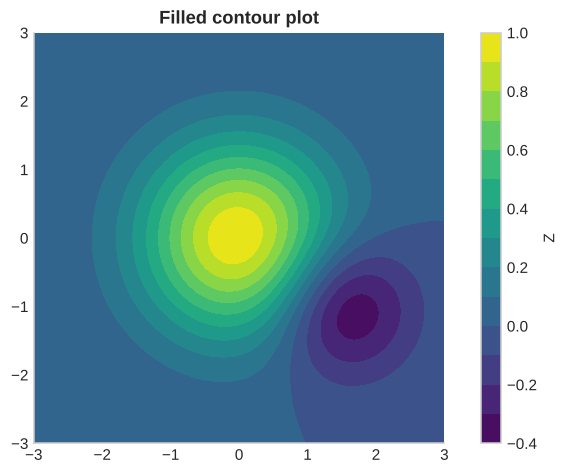

In [33]:
x = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x, x)
Z = np.exp(-(X ** 2 + Y ** 2) / 2) - 0.5 * np.exp(-((X - 1.5) ** 2 + (Y + 1) ** 2))
fig, ax = plt.subplots()
cf = ax.contourf(X, Y, Z, levels=15, cmap="viridis")
fig.colorbar(cf, ax=ax, label="Z")
ax.set_aspect("equal")
ax.set_title("Filled contour plot")

### 34. Scatter with marginal histograms

A GridSpec layout puts the distribution of each variable on the margins.

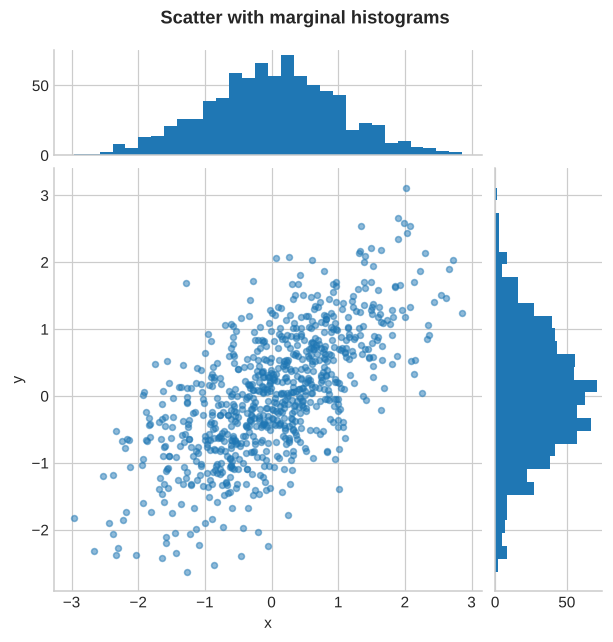

In [34]:
rng = np.random.default_rng(12)
x = rng.normal(size=800)
y = 0.7 * x + rng.normal(0, 0.7, 800)
fig = plt.figure(figsize=(6, 6), layout="none")
gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4),
                      left=0.12, right=0.95, bottom=0.1, top=0.92, hspace=0.05, wspace=0.05)
ax = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax)
ax.scatter(x, y, alpha=0.5, s=15)
ax_top.hist(x, bins=30)
ax_right.hist(y, bins=30, orientation="horizontal")
ax_top.tick_params(labelbottom=False)
ax_right.tick_params(labelleft=False)
ax.set(xlabel="x", ylabel="y")
fig.suptitle("Scatter with marginal histograms", fontweight="bold")

## Layout & Styling

### 35. Subplot grid

Loop over `axes.flat` to fill a grid without repeating code.

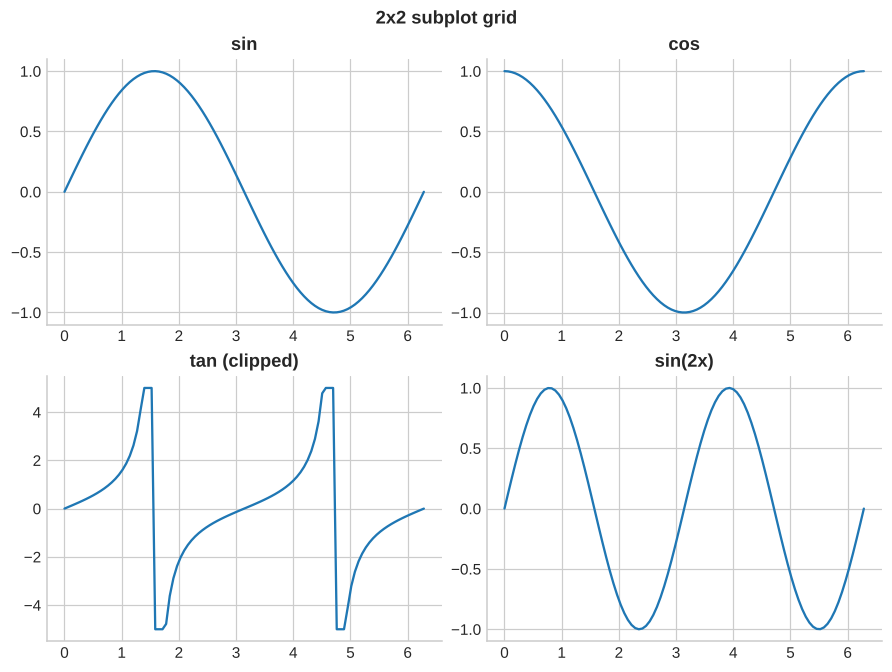

In [35]:
x = np.linspace(0, 2 * np.pi, 100)
funcs = [("sin", np.sin), ("cos", np.cos),
         ("tan (clipped)", lambda t: np.clip(np.tan(t), -5, 5)),
         ("sin(2x)", lambda t: np.sin(2 * t))]
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, (name, f) in zip(axes.flat, funcs):
    ax.plot(x, f(x))
    ax.set_title(name)
fig.suptitle("2x2 subplot grid", fontweight="bold")

### 36. Shared axes

`sharex=True` aligns the panels and hides redundant tick labels.

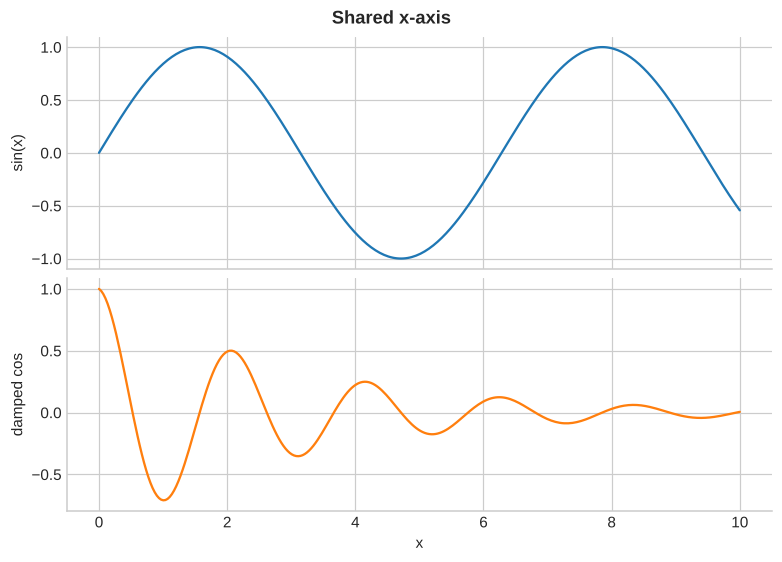

In [36]:
x = np.linspace(0, 10, 300)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
ax1.plot(x, np.sin(x))
ax1.set_ylabel("sin(x)")
ax2.plot(x, np.exp(-x / 3) * np.cos(3 * x), color="tab:orange")
ax2.set_ylabel("damped cos")
ax2.set_xlabel("x")
fig.suptitle("Shared x-axis", fontweight="bold")

### 37. GridSpec with uneven panels

Span rows and columns to build dashboard-style layouts.

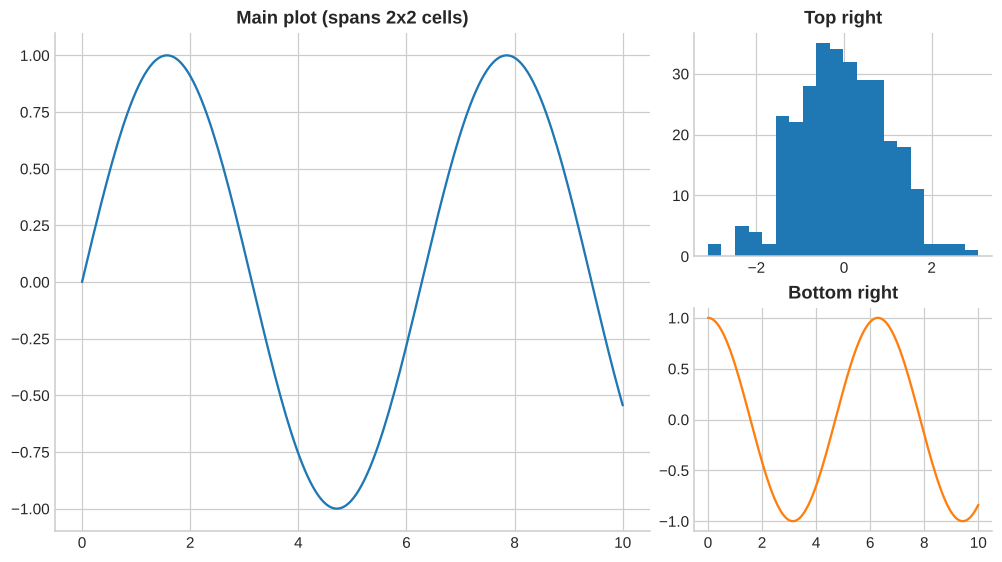

In [37]:
x = np.linspace(0, 10, 200)
fig = plt.figure(figsize=(9, 5))
gs = fig.add_gridspec(2, 3)
ax_big = fig.add_subplot(gs[:, :2])
ax_a = fig.add_subplot(gs[0, 2])
ax_b = fig.add_subplot(gs[1, 2])
ax_big.plot(x, np.sin(x))
ax_big.set_title("Main plot (spans 2x2 cells)")
ax_a.hist(np.random.default_rng(0).normal(size=300), bins=20)
ax_a.set_title("Top right")
ax_b.plot(x, np.cos(x), color="tab:orange")
ax_b.set_title("Bottom right")

### 38. Inset zoom

Magnify a region of interest inside the main axes.

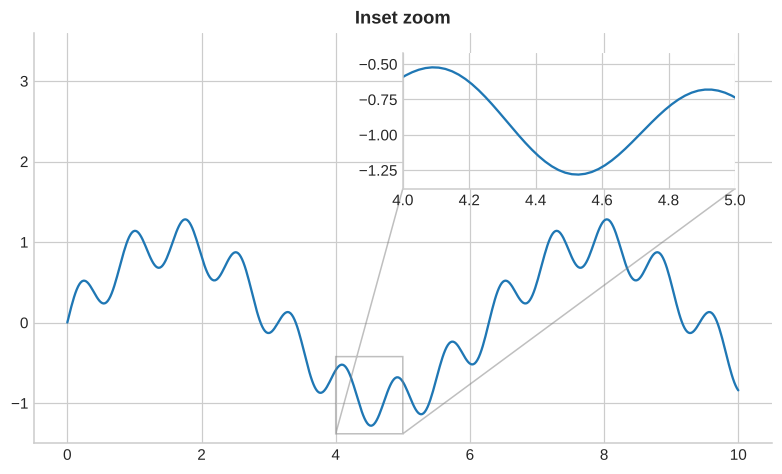

In [38]:
x = np.linspace(0, 10, 500)
y = np.sin(x) + 0.3 * np.sin(8 * x)
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set_ylim(-1.5, 3.6)                      # leave headroom for the inset
axins = ax.inset_axes([0.5, 0.62, 0.45, 0.33])
axins.plot(x, y)
mask = (x >= 4) & (x <= 5)
axins.set_xlim(4, 5)
axins.set_ylim(y[mask].min() - 0.1, y[mask].max() + 0.1)
ax.indicate_inset_zoom(axins)
ax.set_title("Inset zoom")

### 39. Linear vs log scale

Log axes turn power laws into straight lines.

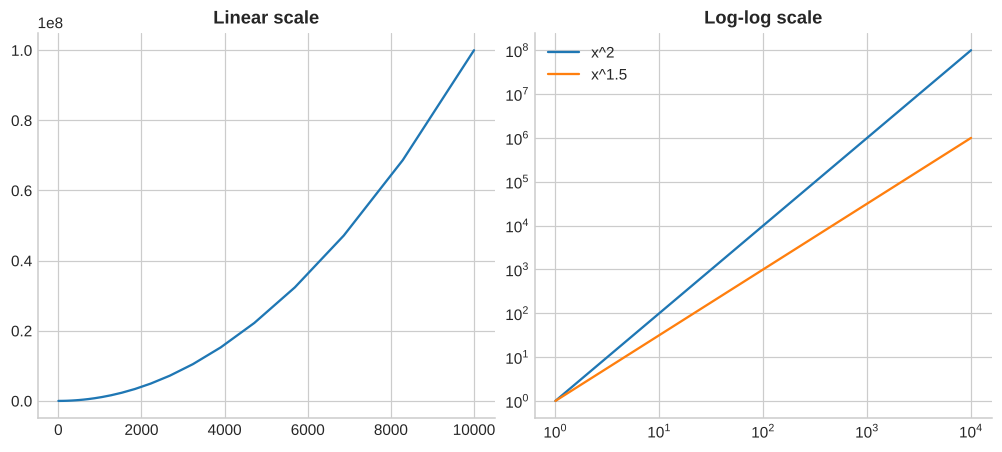

In [39]:
x = np.logspace(0, 4, 50)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ax1.plot(x, x ** 2)
ax1.set_title("Linear scale")
ax2.loglog(x, x ** 2, label="x^2")
ax2.loglog(x, x ** 1.5, label="x^1.5")
ax2.legend()
ax2.set_title("Log-log scale")

### 40. Custom theme with rc_context

Apply a dark theme to one figure only, without touching global settings.

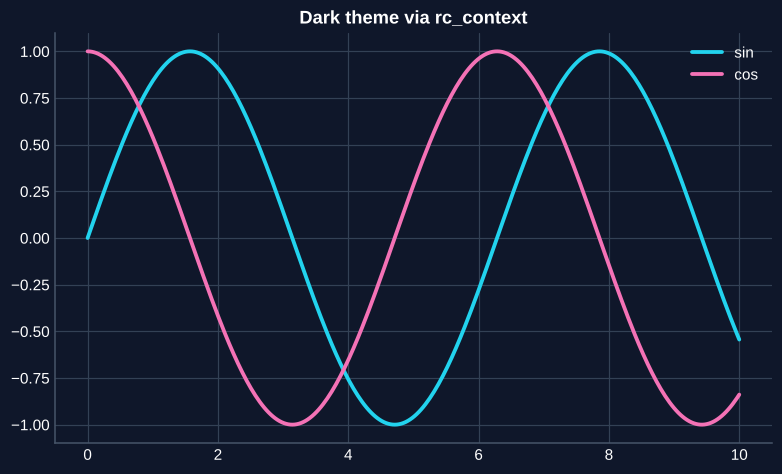

In [40]:
x = np.linspace(0, 10, 300)
theme = {"axes.facecolor": "#0f172a", "figure.facecolor": "#0f172a",
         "text.color": "white", "axes.labelcolor": "white",
         "xtick.color": "white", "ytick.color": "white",
         "axes.edgecolor": "#475569", "grid.color": "#334155"}
with plt.rc_context(theme):
    fig, ax = plt.subplots()
    ax.plot(x, np.sin(x), color="#22d3ee", linewidth=2.5, label="sin")
    ax.plot(x, np.cos(x), color="#f472b6", linewidth=2.5, label="cos")
    ax.legend(facecolor="#1e293b", edgecolor="#475569")
    ax.set_title("Dark theme via rc_context")

## Specialized Charts

### 41. Radar chart

Polar axes with a closed polygon to compare profiles.

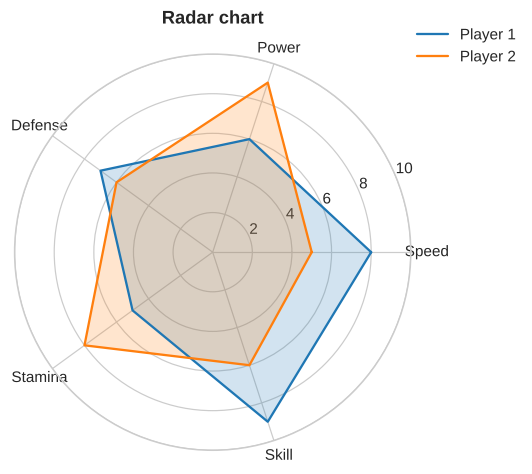

In [41]:
labels = ["Speed", "Power", "Defense", "Stamina", "Skill"]
players = {"Player 1": [8, 6, 7, 5, 9], "Player 2": [5, 9, 6, 8, 6]}
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(subplot_kw={"projection": "polar"})
for name, vals in players.items():
    v = vals + vals[:1]
    ax.plot(angles, v, label=name)
    ax.fill(angles, v, alpha=0.2)
ax.set_xticks(angles[:-1], labels)
ax.set_ylim(0, 10)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
ax.set_title("Radar chart", pad=20)

### 42. Stem plot

Good for discrete signals and sequences.

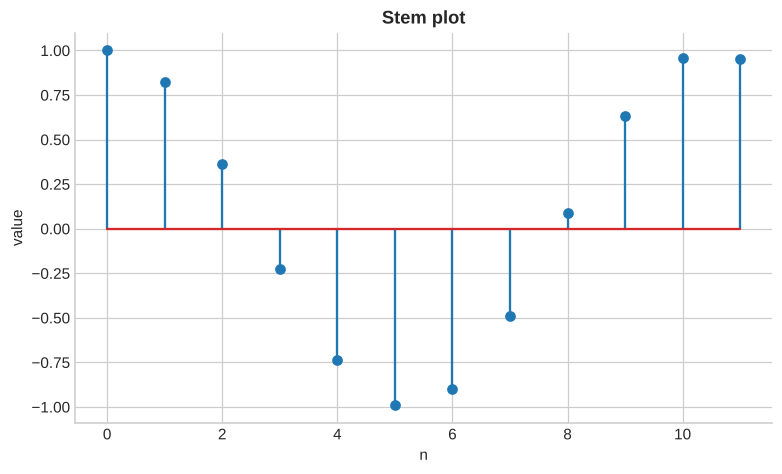

In [42]:
x = np.arange(0, 12)
y = np.cos(x * 0.6)
fig, ax = plt.subplots()
ax.stem(x, y)
ax.set(title="Stem plot", xlabel="n", ylabel="value")

### 43. Quiver plot (vector field)

Arrows show direction, and colour can show magnitude.

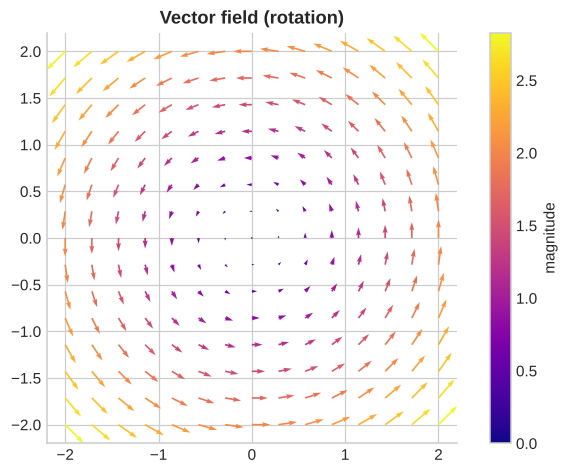

In [43]:
x, y = np.meshgrid(np.linspace(-2, 2, 15), np.linspace(-2, 2, 15))
u, v = -y, x
fig, ax = plt.subplots()
q = ax.quiver(x, y, u, v, np.hypot(u, v), cmap="plasma")
fig.colorbar(q, ax=ax, label="magnitude")
ax.set_aspect("equal")
ax.set_title("Vector field (rotation)")

### 44. Streamplot

Flow lines through a vector field, coloured by speed.

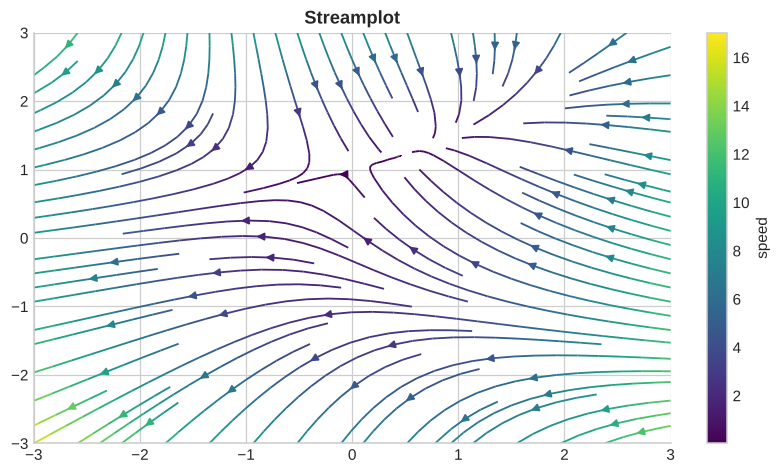

In [44]:
Y, X = np.mgrid[-3:3:100j, -3:3:100j]
U = -1 - X ** 2 + Y
V = 1 + X - Y ** 2
speed = np.hypot(U, V)
fig, ax = plt.subplots()
strm = ax.streamplot(X, Y, U, V, color=speed, cmap="viridis", linewidth=1.2)
fig.colorbar(strm.lines, ax=ax, label="speed")
ax.set_title("Streamplot")

### 45. 3D surface

Surface plots need a 3D projection and a meshgrid.

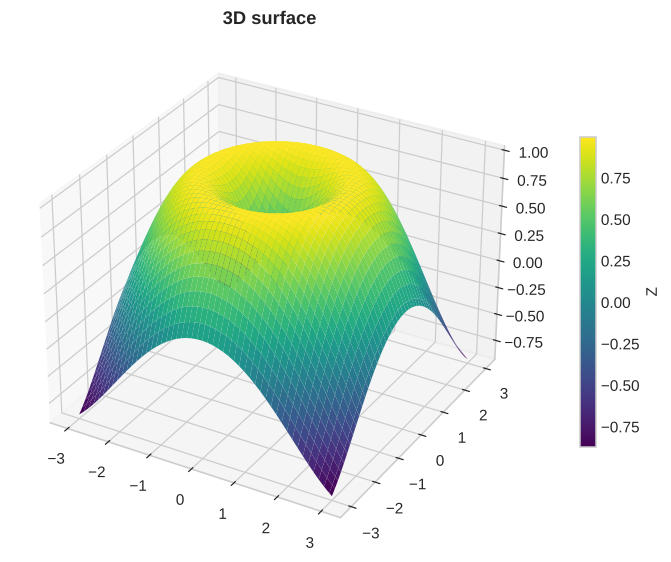

In [45]:
x = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, x)
Z = np.sin(np.sqrt(X ** 2 + Y ** 2))
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none")
fig.colorbar(surf, shrink=0.6, label="Z")
ax.set_title("3D surface")

### 46. 3D scatter

Colour points by a computed value, like distance from the origin.

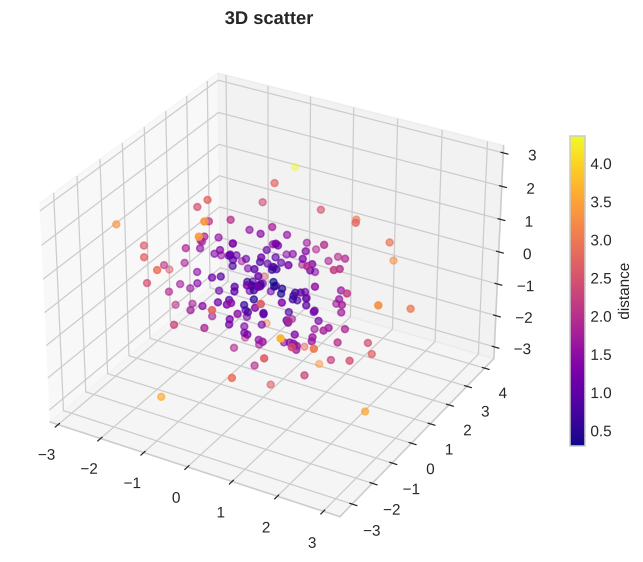

In [46]:
rng = np.random.default_rng(13)
pts = rng.normal(size=(200, 3))
dist = np.linalg.norm(pts, axis=1)
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
sc = ax.scatter(*pts.T, c=dist, cmap="plasma")
fig.colorbar(sc, shrink=0.6, label="distance")
ax.set_title("3D scatter")

### 47. imshow with colorbar

Display any 2D array as an image, with real-world axis extents.

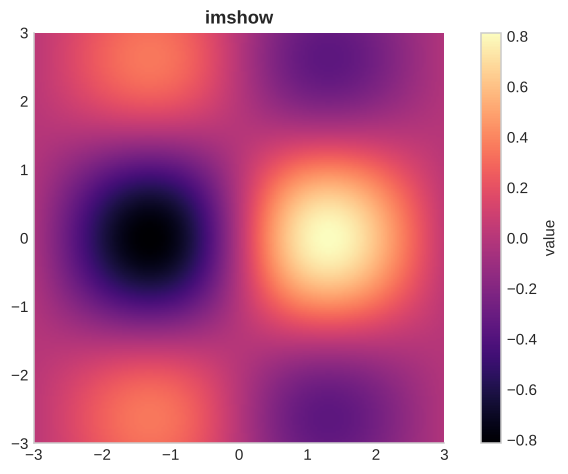

In [47]:
x = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x, x)
Z = np.sin(X) * np.cos(Y) * np.exp(-0.1 * (X ** 2 + Y ** 2))
fig, ax = plt.subplots()
im = ax.imshow(Z, cmap="magma", origin="lower", extent=[-3, 3, -3, 3])
fig.colorbar(im, ax=ax, label="value")
ax.grid(False)
ax.set_title("imshow")

### 48. Gantt-style timeline

Horizontal bars with a `left` offset make a simple project schedule.

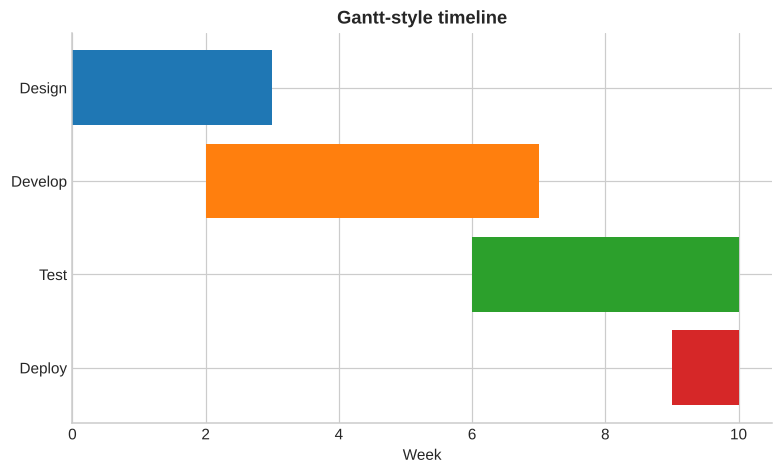

In [48]:
tasks = ["Design", "Develop", "Test", "Deploy"]
start = [0, 2, 6, 9]
duration = [3, 5, 4, 1]
fig, ax = plt.subplots()
ax.barh(tasks, duration, left=start,
        color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
ax.invert_yaxis()
ax.set(title="Gantt-style timeline", xlabel="Week")

### 49. Waterfall chart

Floating bars show how a starting value changes step by step.

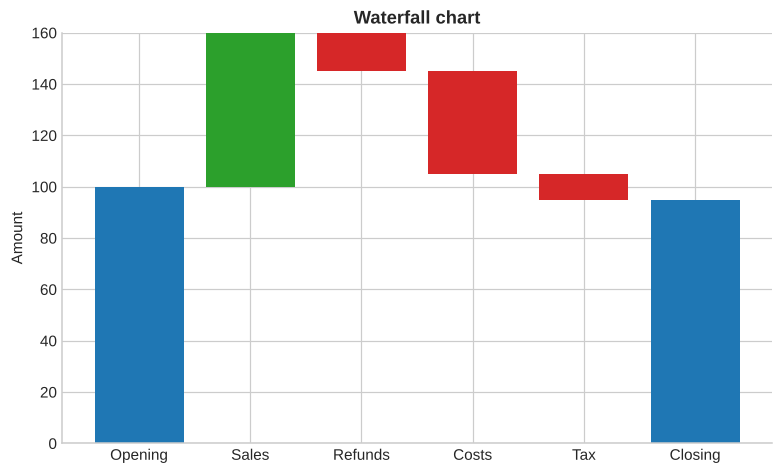

In [49]:
labels = ["Opening", "Sales", "Refunds", "Costs", "Tax", "Closing"]
steps = [60, -15, -40, -10]
opening = 100
levels = opening + np.concatenate([[0], np.cumsum(steps)])
fig, ax = plt.subplots()
ax.bar(0, opening, color="tab:blue")
for i, d in enumerate(steps, start=1):
    ax.bar(i, d, bottom=levels[i - 1], color="tab:green" if d > 0 else "tab:red")
ax.bar(len(steps) + 1, levels[-1], color="tab:blue")
ax.set_xticks(range(len(labels)), labels)
ax.set(title="Waterfall chart", ylabel="Amount")

### 50. Dumbbell chart

Compare before and after values per category in one glance.

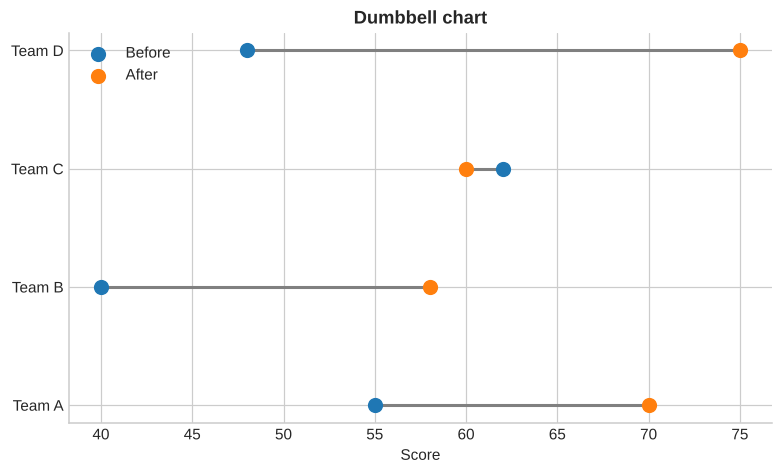

In [50]:
cats = ["Team A", "Team B", "Team C", "Team D"]
before = np.array([55, 40, 62, 48])
after = np.array([70, 58, 60, 75])
y = np.arange(len(cats))
fig, ax = plt.subplots()
ax.hlines(y, before, after, color="gray", linewidth=2)
ax.scatter(before, y, s=80, label="Before", zorder=3)
ax.scatter(after, y, s=80, label="After", zorder=3)
ax.set_yticks(y, cats)
ax.legend()
ax.set(title="Dumbbell chart", xlabel="Score")